# Lab 5: Image Classification with CNNs

*Written by Sai Raj Kishore Perla, modified by Yalda.*

In this lab you will teach a computer to look at a small picture and say what it is: *cat*, *ship*, *truck*...

1. **What is classification?** Try a model that is already trained.
2. **Convolution.** The building block of every CNN. You will write it yourself.
3. **Building a CNN.** Conv, ReLU, pooling and a final layer.
4. **Train your own CNN** on CIFAR-10.
5. **Transfer learning.** Reuse a big pretrained network (ResNet18) and compare.
6. **Look inside.** What did the network learn, and where does it make mistakes?

| Part | Time |
|---|---|
| Setup + 1. Classification | 20 min |
| 2. Convolution | 30 min |
| 3. Building a CNN | 15 min |
| 4. Train your own CNN | 30 min |
| 5. Transfer learning | 15 min |
| 6. Look inside | 10 min |

For each **TODO**, write your code, then run the check cell. The solutions are hidden; open them only after you try.
A GPU makes training faster, but everything also runs on a CPU.

## Setup

In [ ]:
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from IPython.display import IFrame

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():   # Apple GPU
    device = "mps"
else:
    device = "cpu"
print("device:", device)

### The dataset: CIFAR-10

60,000 tiny color images (32×32 pixels) in **10 classes**. The full dataset is slow to download, so we use a
small balanced part of it: **5,000 training images** (500 per class) and **1,000 test images** (100 per class), about 17 MB.

- **Training set**: the images the model learns from.
- **Test set**: images the model has *never seen*. We use them to check whether it really learned.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/arash-mham/visual-computing-I/main/lab-material/lab5/cifar10_small.npz"
if not os.path.exists("cifar10_small.npz"):
    urllib.request.urlretrieve(DATA_URL, "cifar10_small.npz")

data = np.load("cifar10_small.npz")
x_train = data["x_train"]   # (5000, 32, 32, 3) uint8 images
y_train = data["y_train"]   # (5000,) labels 0..9
x_test = data["x_test"]     # (1000, 32, 32, 3)
y_test = data["y_test"]     # (1000,)
classes = [str(c) for c in data["classes"]]

print("train:", x_train.shape, " test:", x_test.shape)
print("classes:", classes)

In [ ]:
# one row of examples per class
fig, axes = plt.subplots(10, 8, figsize=(8, 10))
for c in range(10):
    idx = np.where(y_train == c)[0][:8]
    for j in range(8):
        axes[c, j].imshow(x_train[idx[j]])
        axes[c, j].axis("off")
    axes[c, 0].set_title(classes[c], loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## 1. What is image classification?

**Input:** an image. **Output:** one label from a fixed list of classes.

A classifier does not output the label directly. It outputs **one score per class** (also called *logits*).
A higher score means "more likely". The pipeline is:

$$\text{image} \;\rightarrow\; \text{model} \;\rightarrow\; \text{scores } (z_1, \dots, z_K) \;\rightarrow\; \text{softmax} \;\rightarrow\; \text{probabilities} \;\rightarrow\; \text{pick the largest}$$

Let's try a model that is **already trained**: ResNet18, trained on ImageNet (1.2 million photos, **1000 classes**).

In [ ]:
weights = ResNet18_Weights.DEFAULT
imagenet_model = resnet18(weights=weights).to(device)
imagenet_model.eval()
imagenet_classes = weights.meta["categories"]   # the 1000 class names
preprocess = weights.transforms()               # resize + normalize, the way the model was trained

IMG_URL = "https://raw.githubusercontent.com/arash-mham/visual-computing-I/main/lab-material/lab5/dog.jpg"
if not os.path.exists("dog.jpg"):
    urllib.request.urlretrieve(IMG_URL, "dog.jpg")
img = Image.open("dog.jpg").convert("RGB")
plt.imshow(img)
plt.axis("off")
plt.show()

x = preprocess(img).unsqueeze(0).to(device)   # add a batch dimension: (1, 3, 224, 224)
with torch.no_grad():
    scores = imagenet_model(x)[0].cpu()
print("number of scores:", scores.shape)
print("first 5 scores:", scores[:5])

Scores can be any number, positive or negative. **Softmax** turns them into probabilities (all positive, sum to 1):

$$p_i = \frac{e^{z_i}}{\sum_{j} e^{z_j}}$$

**TODO 1:** write `my_softmax`.

In [ ]:
def my_softmax(scores):
    # scores: 1D tensor of raw scores
    # TODO: make every score positive with torch.exp
    exp_scores = ...
    # TODO: divide by the sum so the values add up to 1
    probs = ...
    return probs

#### Solution

Try it yourself first, then open the hidden cell below.

In [ ]:
#@title Solution

def my_softmax(scores):
    # scores: 1D tensor of raw scores
    exp_scores = torch.exp(scores)
    probs = exp_scores / exp_scores.sum()
    return probs

In [ ]:
# run this cell to check your code
t = torch.tensor([2.0, -1.0, 0.5, 3.0])
print("correct:", torch.allclose(my_softmax(t), torch.softmax(t, dim=0)))

In [ ]:
probs = my_softmax(scores)
top = torch.topk(probs, 5)
names = [imagenet_classes[i] for i in top.indices]

plt.barh(names[::-1], top.values.numpy()[::-1])
plt.xlabel("probability")
plt.title("Top-5 predictions")
plt.show()

Look at the runner-up: **Labrador retriever**, a dog that looks very similar. The model is not just right; its mistakes are "reasonable" too.

**Try it:** upload your own photo, change `"dog.jpg"` above to its file name, and run the cells again.
Can you fool the model? It can only choose from its 1000 ImageNet classes, and it never says "I don't know".
For example, there is no "dachshund" or "person" class. What does it say for a photo of one?

*Photo: "Golden Retriever 2020 5" by Johannnes89, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), via Wikimedia Commons.*

## 2. Convolution

In Lab 2 you used the **Sobel filter** to find edges. That was a convolution:

1. Put a small grid of numbers (the **kernel**, here 3×3) on top of the image.
2. Multiply each kernel number with the pixel under it, and **add everything up**. That is one output pixel.
3. Slide the kernel one step and repeat.

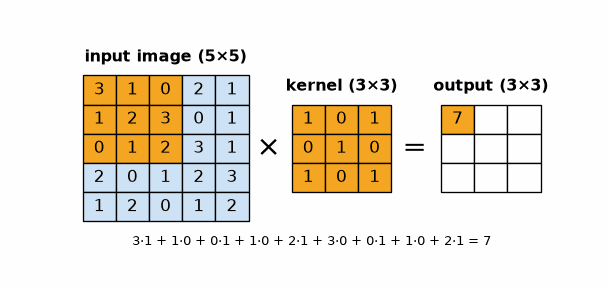

The orange 3×3 window on the input is multiplied with the kernel, number by number, and the products are added.
The result is one output pixel. Then the window slides one step.

A 3×3 kernel fits in only $5 - 3 + 1 = 3$ positions across a 5×5 image, so the output is 3×3.
In general a $k \times k$ kernel on an $H \times W$ image gives an output of size $(H-k+1) \times (W-k+1)$.

**TODO 2:** write `conv2d` with two loops.

In [ ]:
def conv2d(image, kernel):
    # image: 2D array (H, W), kernel: 2D array (k, k)
    H, W = image.shape
    k = kernel.shape[0]
    out_h = H - k + 1
    out_w = W - k + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            # TODO: take the k x k patch of the image whose top-left corner is (i, j)
            patch = ...
            # TODO: multiply the patch and the kernel element by element, then sum
            out[i, j] = ...
    return out

#### Solution

Try it yourself first, then open the hidden cell below.

In [ ]:
#@title Solution

def conv2d(image, kernel):
    # image: 2D array (H, W), kernel: 2D array (k, k)
    H, W = image.shape
    k = kernel.shape[0]
    out_h = H - k + 1
    out_w = W - k + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i:i + k, j:j + k]
            out[i, j] = np.sum(patch * kernel)
    return out

In [ ]:
# run this cell to check your code (compare with PyTorch's convolution)
img_test = np.random.rand(6, 7)
ker_test = np.random.rand(3, 3)
mine = conv2d(img_test, ker_test)
torch_out = F.conv2d(torch.tensor(img_test)[None, None], torch.tensor(ker_test)[None, None])[0, 0].numpy()
print("correct:", mine.shape == (4, 5) and np.allclose(mine, torch_out))

Now use your function with a few hand-made kernels on a real image. Each kernel finds a different thing.

In [ ]:
gray = Image.open("dog.jpg").convert("L")
gray = gray.resize((256, int(256 * gray.height / gray.width)))
gray = np.array(gray) / 255.0

kernels = {
    "blur": np.ones((3, 3)) / 9,
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Sobel x (vertical edges)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Sobel y (horizontal edges)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
}

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("input")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    ax.imshow(conv2d(gray, k), cmap="gray")
    ax.set_title(name)
for ax in axes:
    ax.axis("off")
plt.show()

> **The big idea of a CNN:** we do **not** choose the kernel numbers by hand.
> The network starts with random kernels and **learns** the numbers that help it classify.

### Padding and stride

- **Padding** $P$: add a border of zeros so the output can stay the same size as the input.
- **Stride** $S$: move the kernel $S$ pixels at a time. Stride 2 makes the output about half as big.

Same input and kernel as above:

**Padding 1, stride 1:** the gray zeros let the kernel sit on the border pixels too, so the output stays 5×5.

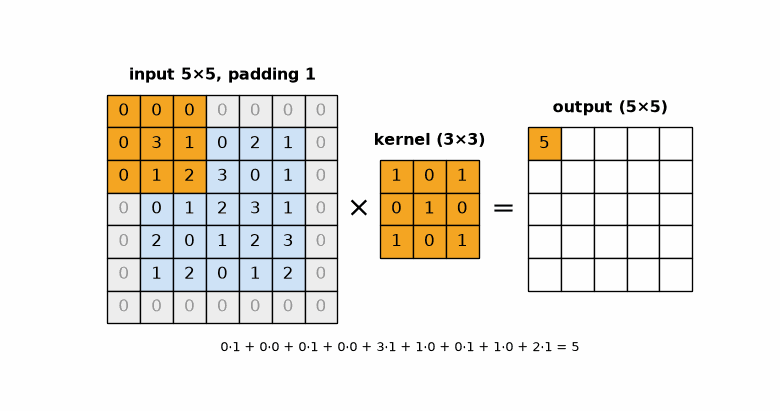

**Padding 0, stride 2:** the kernel jumps 2 pixels at a time, so the output is only 2×2.

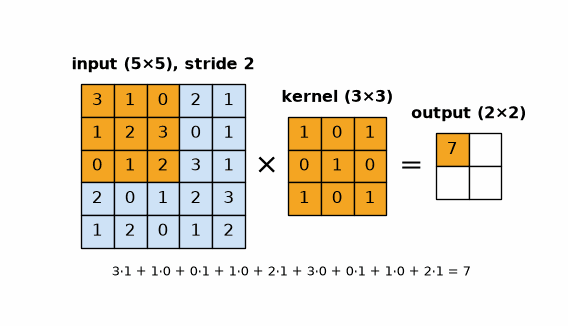

For an input of width $W$ and a kernel of size $K$:

$$W_{out} = \left\lfloor \frac{W + 2P - K}{S} \right\rfloor + 1$$

**TODO 3:** write the formula.

In [ ]:
def conv_output_size(W, K, P, S):
    # TODO: use the formula above (hint: // is integer division)
    return ...

#### Solution

Try it yourself first, then open the hidden cell below.

In [ ]:
#@title Solution

def conv_output_size(W, K, P, S):
    return (W + 2 * P - K) // S + 1

In [ ]:
# run this cell to check your code (compare with a real nn.Conv2d layer)
ok = True
for W, K, P, S in [(32, 3, 0, 1), (32, 3, 1, 1), (32, 5, 2, 2), (28, 7, 3, 2), (224, 7, 3, 2)]:
    layer = nn.Conv2d(1, 1, kernel_size=K, padding=P, stride=S)
    real = layer(torch.zeros(1, 1, W, W)).shape[-1]
    ok = ok and conv_output_size(W, K, P, S) == real
print("correct:", ok)

### Color images and many kernels

A color image has **3 channels** (R, G, B), so each kernel is $3 \times K \times K$: it looks at all channels at once.
The kernel has one 3×3 slice per channel. Each slice is applied to its own channel, and the three results are
**added** into one number. So one kernel gives **one** output image, even though the input has 3 channels.

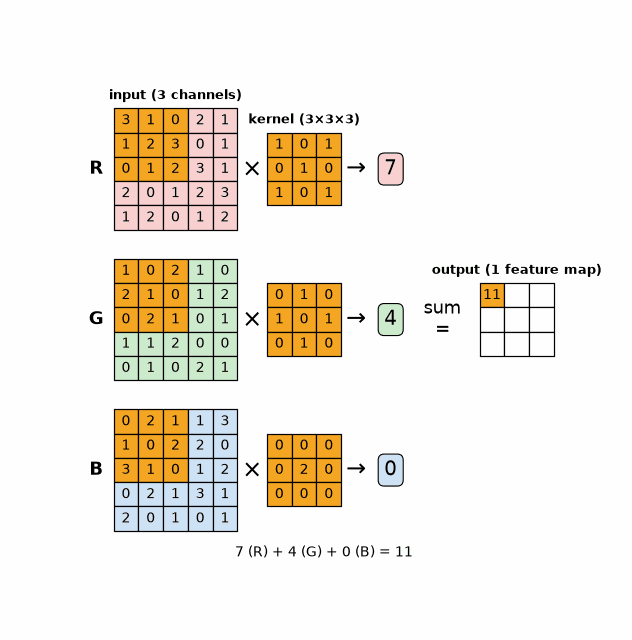

A conv layer uses **many kernels**; each one gives one output image, called a **feature map**.

`nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)` has 16 kernels of size $3 \times 3 \times 3$, plus one bias each:
$16 \times (3 \cdot 3 \cdot 3 + 1)$ numbers to learn.

In [ ]:
layer = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
batch = torch.zeros(8, 3, 32, 32)   # 8 color images of size 32x32
print("input shape: ", batch.shape)
print("output shape:", layer(batch).shape)    # 16 feature maps per image
print("kernel shape:", layer.weight.shape)
print("parameters:  ", sum(p.numel() for p in layer.parameters()))

## 3. Building a CNN

A CNN stacks a few simple blocks:

| Block | What it does | PyTorch |
|---|---|---|
| **Convolution** | finds patterns (edges, colors, textures, then parts of objects) | `nn.Conv2d` |
| **ReLU** | keeps positive values, sets negative values to 0 | `nn.ReLU` |
| **Max pooling** | keeps the largest value in each 2×2 window, so the image becomes half as big | `nn.MaxPool2d(2)` |
| **Flatten + Linear** | turns the last feature maps into one score per class | `torch.flatten`, `nn.Linear` |

Early layers find simple things like edges. Deeper layers combine them into eyes, wheels, wings...

**Explore (5 min):** watch the short video, then open [CNN Explainer](https://poloclub.github.io/cnn-explainer/).
Click a neuron in a conv layer to watch the kernel slide, and find the ReLU and max-pool layers.
For a 3D view, draw a digit in [Adam Harley's CNN visualizer](https://adamharley.com/nn_vis/cnn/3d.html).

**CNN Explainer demo (2 min)** (click to watch)

<a href="https://www.youtube.com/watch?v=HnWIHWFbuUQ" target="_blank"><img src="https://img.youtube.com/vi/HnWIHWFbuUQ/hqdefault.jpg" width="480"></a>

Here are ReLU and max pooling applied to the Sobel output from Part 2:

In [ ]:
edges = torch.tensor(conv2d(gray, kernels["Sobel x (vertical edges)"]))[None, None]   # (1, 1, H, W)
after_relu = nn.ReLU()(edges)
after_pool = nn.MaxPool2d(2)(after_relu)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, t, name in zip(axes, [edges, after_relu, after_pool], ["conv (Sobel x)", "ReLU", "max pool 2x2"]):
    ax.imshow(t[0, 0], cmap="gray")
    ax.set_title(f"{name}  {tuple(t.shape[-2:])}")
    ax.axis("off")
plt.show()

## 4. Train your own CNN on CIFAR-10

First, turn the images into PyTorch tensors:
- reorder to `(N, 3, 32, 32)` (PyTorch puts channels first),
- scale to [0, 1], then normalize each channel,
- wrap in a `DataLoader` that gives batches of 64 images.

In [ ]:
# average and spread of R, G, B over ImageNet photos; the pretrained ResNet18 expects inputs normalized this way
# shape (1, 3, 1, 1) so it is applied to every image and every pixel, one value per channel
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_tensor(x):
    x = torch.tensor(x)          # NumPy array -> PyTorch tensor
    x = x.permute(0, 3, 1, 2)    # (N, 32, 32, 3) -> (N, 3, 32, 32): PyTorch wants channels first
    x = x.float() / 255          # uint8 0..255 -> float 0..1
    x = (x - mean) / std         # center each channel around 0, which helps training
    return x

# pair every image with its label
train_set = TensorDataset(to_tensor(x_train), torch.tensor(y_train))
test_set = TensorDataset(to_tensor(x_test), torch.tensor(y_test))
# give the data in batches of 64; shuffle so every epoch sees the images in a new order
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
# no shuffle needed for testing; bigger batches are fine because we do not compute gradients
test_loader = DataLoader(test_set, batch_size=256)

# look at one batch: 64 images of shape (3, 32, 32) and their 64 labels
images, labels = next(iter(train_loader))
print("one batch:", images.shape, labels.shape)

**TODO 4:** build this network. Each block is **conv (3×3, padding 1) → ReLU → max pool**:

| Layer | Output shape |
|---|---|
| input | 3 × 32 × 32 |
| block 1: `Conv2d(3, 16)` → ReLU → pool | 16 × 16 × 16 |
| block 2: `Conv2d(16, 32)` → ReLU → pool | 32 × 8 × 8 |
| block 3: `Conv2d(32, 64)` → ReLU → pool | 64 × 4 × 4 |
| flatten | 1024 |
| `Linear(1024, 10)` | 10 scores |

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        # TODO: conv2 (16 -> 32 channels) and conv3 (32 -> 64 channels), kernel 3, padding 1
        self.conv2 = ...
        self.conv3 = ...
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        # TODO: final layer, 64 * 4 * 4 inputs -> 10 scores
        self.fc = ...

    def forward(self, x):
        # block 1: 3 x 32 x 32 -> 16 x 16 x 16
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        # TODO: block 2 (-> 32 x 8 x 8), same three steps with conv2

        # TODO: block 3 (-> 64 x 4 x 4), same three steps with conv3

        x = torch.flatten(x, 1)   # (batch, 1024)
        x = self.fc(x)            # (batch, 10)
        return x

#### Solution

Try it yourself first, then open the hidden cell below.

In [ ]:
#@title Solution

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(64 * 4 * 4, 10)

    def forward(self, x):
        # block 1: 3 x 32 x 32 -> 16 x 16 x 16
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        # block 2: -> 32 x 8 x 8
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)
        # block 3: -> 64 x 4 x 4
        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)   # (batch, 1024)
        x = self.fc(x)            # (batch, 10)
        return x

In [ ]:
# run this cell to check your code
m = SimpleCNN()
n_params = sum(p.numel() for p in m.parameters())
print("output shape:", m(torch.zeros(8, 3, 32, 32)).shape, " parameters:", n_params)
print("correct:", m(torch.zeros(8, 3, 32, 32)).shape == (8, 10) and n_params == 33834)

### Loss and training

The **cross-entropy loss** looks at the probability the model gives to the **correct** class, $p_{\text{true}}$:

$$\text{loss} = -\log(p_{\text{true}})$$

If $p_{\text{true}} = 0.9$, the loss is $0.11$ (good). If $p_{\text{true}} = 0.1$, the loss is $2.3$ (bad).
`nn.CrossEntropyLoss` applies softmax for you, so give it the raw scores.

Training repeats, for every batch: **forward pass → loss → backward pass (gradients) → update the weights**.
One pass over the whole training set is called an **epoch**.

**TODO 5:** fill in the training step. For each batch:

1. Move `images` and `labels` to `device` (the model is already there).
2. Forward pass, then compute the loss.
3. Clear old gradients, backpropagate, update the weights.

In [ ]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    for images, labels in loader:
        # TODO: move images and labels to device
        images = ...
        labels = ...
        # TODO: forward pass, scores has shape (batch, 10)
        scores = ...
        # TODO: compute the loss with criterion
        loss = ...
        # TODO: the three training steps:
        #       1. clear old gradients  2. backpropagate  3. update the weights
        ...
        ...
        ...
        total_loss += loss.item() * len(labels)
        correct += (scores.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

#### Solution

Try it yourself first, then open the hidden cell below.

In [ ]:
#@title Solution

criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        scores = model(images)
        loss = criterion(scores, labels)
        optimizer.zero_grad()   # clear old gradients
        loss.backward()         # backpropagate
        optimizer.step()        # update the weights
        total_loss += loss.item() * len(labels)
        correct += (scores.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

In [ ]:
# run this cell to check your code (one short epoch on 640 images)
torch.manual_seed(0)
m = SimpleCNN().to(device)
before = m.fc.weight.detach().clone()
small_loader = DataLoader(TensorDataset(*train_set[:640]), batch_size=64)
loss, acc = train_one_epoch(m, small_loader, optim.Adam(m.parameters(), lr=1e-3))
print("loss:", round(loss, 3))
print("correct:", 0 < loss < 3 and not torch.equal(before, m.fc.weight.detach()))

In [ ]:
def evaluate(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():   # no gradients needed for testing
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            scores = model(images)
            correct += (scores.argmax(dim=1) == labels).sum().item()
    return correct / len(loader.dataset)


def train(model, optimizer, num_epochs):
    history = {"loss": [], "train_acc": [], "test_acc": []}
    for epoch in range(num_epochs):
        loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        test_acc = evaluate(model, test_loader)
        history["loss"].append(loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        print(f"epoch {epoch + 1:2d} | loss {loss:.3f} | train acc {train_acc:.2f} | test acc {test_acc:.2f}")
    return history


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(history["loss"])
    axes[0].set_title("training loss")
    axes[0].set_xlabel("epoch")
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["test_acc"], label="test")
    axes[1].axhline(0.1, color="gray", linestyle="--", label="random guess")
    axes[1].set_title("accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    fig.suptitle(title)
    plt.show()

Now train your CNN for 15 epochs (a few seconds on a GPU, about a minute on a CPU).

In [ ]:
torch.manual_seed(0)
cnn = SimpleCNN().to(device)
optimizer = optim.Adam(cnn.parameters(), lr=1e-3)
cnn_history = train(cnn, optimizer, num_epochs=15)
plot_history(cnn_history, "SimpleCNN (trained from scratch)")

**Think:** random guessing gives 10%. How far did you get?
Train accuracy keeps going up, but test accuracy stops improving. The model starts to **memorize** the training
images instead of learning general rules. This is called **overfitting**, and we will fight it in Classification 2.

## 5. Transfer learning: reuse a pretrained network

Our CNN learned from only 5,000 images. ResNet18 has already learned edges, textures and shapes from 1.2 million
ImageNet photos. We can **reuse** all of that and only swap the last layer: ImageNet has 1000 classes, we have 10.

**TODO 6:** replace the last layer `resnet.fc` with a new `nn.Linear` that outputs 10 scores.

In [ ]:
torch.manual_seed(0)
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
print("old last layer:", resnet.fc)
# TODO: replace resnet.fc with a new layer that outputs 10 scores
#       (hint: resnet.fc.in_features is the number of inputs it needs)
resnet.fc = ...
resnet = resnet.to(device)

#### Solution

Try it yourself first, then open the hidden cell below.

In [ ]:
#@title Solution

torch.manual_seed(0)
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
print("old last layer:", resnet.fc)
resnet.fc = nn.Linear(resnet.fc.in_features, 10)
resnet = resnet.to(device)

In [ ]:
# run this cell to check your code
print("new last layer:", resnet.fc)
print("correct:", isinstance(resnet.fc, nn.Linear) and resnet.fc.in_features == 512 and resnet.fc.out_features == 10)

**Fine-tune** the whole network for 3 epochs. It is much bigger than our CNN, so each epoch takes longer.

In [ ]:
optimizer = optim.SGD(resnet.parameters(), lr=0.01, momentum=0.9)
resnet_history = train(resnet, optimizer, num_epochs=3)
plot_history(resnet_history, "ResNet18 (pretrained, fine-tuned)")

In [ ]:
print(f"SimpleCNN, 15 epochs from scratch : {cnn_history['test_acc'][-1]:.2f}")
print(f"ResNet18, 3 epochs fine-tuned     : {resnet_history['test_acc'][-1]:.2f}")
print("parameters  SimpleCNN:", sum(p.numel() for p in cnn.parameters()),
      "  ResNet18:", sum(p.numel() for p in resnet.parameters()))

**Optional:** ResNet18 was trained on 224×224 photos, but ours are 32×32. Upscale the images inside the model and
fine-tune again. Does it help? (It is slower.)
```python
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, 10)
resnet = nn.Sequential(nn.Upsample(size=64, mode="bilinear"), resnet).to(device)
```

## 6. Look inside

### What does the first layer of ResNet18 look for?

These are the 64 kernels (7×7, color) of ResNet18's first conv layer, learned on ImageNet.
Compare them with the Sobel kernels from Part 2.

In [ ]:
w = imagenet_model.conv1.weight.detach().cpu()    # (64, 3, 7, 7)
fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
for i, ax in enumerate(axes.flat):
    k = w[i].permute(1, 2, 0)                     # (7, 7, 3) for imshow
    k = (k - k.min()) / (k.max() - k.min())       # scale to [0, 1]
    ax.imshow(k)
    ax.axis("off")
plt.suptitle("ResNet18 first-layer kernels")
plt.show()

Many are **edge detectors** at different angles (like Sobel!), others react to colors. Nobody designed them;
the network learned them from data.

### Feature maps of your CNN

Each of the 16 kernels in your `conv1` makes one feature map. Bright = the kernel's pattern was found there.

In [ ]:
i = 3
image = test_set[i][0].unsqueeze(0).to(device)
with torch.no_grad():
    maps = cnn.relu(cnn.conv1(image))[0].cpu()    # (16, 32, 32)

plt.figure(figsize=(2, 2))
plt.imshow(x_test[i])
plt.title(classes[y_test[i]])
plt.axis("off")
plt.show()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for k, ax in enumerate(axes.flat):
    ax.imshow(maps[k], cmap="gray")
    ax.set_title(f"map {k}", fontsize=9)
    ax.axis("off")
plt.show()

### Where does the model make mistakes?

A **confusion matrix** counts, for every true class (row), how often the model predicted each class (column).
A perfect model only has numbers on the diagonal.

In [ ]:
def predict_all(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for images, labels in loader:
            scores = model(images.to(device))
            preds.append(scores.argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

preds = predict_all(resnet, test_loader)

confusion = np.zeros((10, 10), dtype=int)
for true, pred in zip(y_test, preds):
    confusion[true, pred] += 1

plt.figure(figsize=(7, 6))
plt.imshow(confusion, cmap="Blues")
for r in range(10):
    for c in range(10):
        plt.text(c, r, confusion[r, c], ha="center", va="center", fontsize=8)
plt.xticks(range(10), classes, rotation=45)
plt.yticks(range(10), classes)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("ResNet18 confusion matrix (test set)")
plt.show()

In [ ]:
wrong = np.where(preds != y_test)[0][:12]
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(x_test[i])
    ax.set_title(f"true: {classes[y_test[i]]}\npred: {classes[preds[i]]}", fontsize=9)
    ax.axis("off")
plt.show()

**Think:** which classes get mixed up the most? Would *you* get some of these right at 32×32 pixels?

## Summary

- A classifier gives **one score per class**; **softmax** turns the scores into probabilities.
- A **convolution** slides a small kernel over the image. A CNN **learns** its kernels.
- CNN blocks: **conv → ReLU → pool**, repeated, then a **linear** layer gives the class scores.
- Training: **forward → cross-entropy loss → backward → update**, for many epochs.
- **Transfer learning** (start from a pretrained network) beats training from scratch when you have little data.

**Next lab (Classification 2):** your own dataset, data augmentation against overfitting, and better training.

**Watch at home (3Blue1Brown):** *But what is a convolution?* and *But what is a neural network?*

**3Blue1Brown: But what is a convolution?** (click to watch)

<a href="https://www.youtube.com/watch?v=KuXjwB4LzSA" target="_blank"><img src="https://img.youtube.com/vi/KuXjwB4LzSA/hqdefault.jpg" width="480"></a>

**3Blue1Brown: But what is a neural network?** (click to watch)

<a href="https://www.youtube.com/watch?v=aircAruvnKk" target="_blank"><img src="https://img.youtube.com/vi/aircAruvnKk/hqdefault.jpg" width="480"></a>